In [9]:
import jax
import jax.numpy as jnp 
import WDM
import WDM_LISAresponse
import numpy as np
import matplotlib.pyplot as plt
from WDM_LISAresponse.code.utils.utils import compare_response_signals
from WDM_LISAresponse.code.lisa_response.response_sub import basis_tensors
from WDM_LISAresponse.code.lisa_response.response import one_arm_response_td, one_arm_response_freq_domain, one_arm_response_wdm, one_arm_response_wdm_dT
import time 
from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits
from scipy.signal.windows import tukey


year_SI = 3.154e7

key = jax.random.PRNGKey(0)

In [10]:
def waveform_polarisations(time, A_plus, A_cross, f, phi_0):
    """
    This is for a sine wave signal.

    Parameters
    ----------
    time : ndarray
        time in the solar system barycenter [s]
    A_plus : float
        plus polarisation amplitude [strain]
    A_cross : float
        cross polarisation amplitude [strain]
    f : float
        GW frequency [Hz]
    phi_0 : float
        phase angle [rad]

    Returns
    -------
    h_plus : ndarray
        plus polarised signal, shaped like time.
    h_cross : ndarray
        cross polarised signal, shaped like time.
    """
    h_plus = A_plus * np.cos(2*np.pi*f*time+phi_0)
    h_cross = A_cross * np.sin(2*np.pi*f*time+phi_0)
    return h_plus, h_cross

In [11]:
theta, phi = jnp.array(1.0), jnp.array(1.0)
basis_tensors(theta, phi)

num_points = 100

key, subkey = jax.random.split(key)
theta = jax.random.uniform(key, shape=(num_points,), minval=0.0, maxval=jnp.pi)

key, subkey = jax.random.split(key)
phi = jax.random.uniform(key, shape=(num_points,), minval=0.0, maxval=2*jnp.pi)
polarisation_basis=jnp.zeros((num_points,2, 3, 3))
t_start = time.time()
for i in jnp.arange(num_points):    
    polarisation_basis = polarisation_basis.at[i,:,:,:].set(basis_tensors(theta[i], phi[i]))
    polarisation_basis.block_until_ready()
t_end = time.time()

print(f"Computed {num_points} basis tensors in {t_end - t_start} seconds")

Computed 100 basis tensors in 0.19630885124206543 seconds


In [12]:
#Inject orbital data into our system

orbit_data = read_orbit_file('esa-trailing-orbits.h5')

orbit_times = orbit_data.t0 + orbit_data.dt * np.arange(orbit_data.size)
t_start = orbit_data.t0

orbits_trailing = InterpolatedOrbits(orbit_times, 
                                     orbit_data.positions, 
                                     orbit_data.velocities)

In [13]:
#waveform signal 

theta, phi, A_plus, A_cross, f, phi_0 = np.pi/2, 0.0, 5e-22, 0.0, 1.0e-2, 0.0

t_start = orbit_data.t0+year_SI
#t_end = t_start + 0.001*year_SI
times = np.arange(t_start, t_start+5*5000, 5)
h_plus_td, h_cross_td = waveform_polarisations(times, A_plus, A_cross, f, phi_0)
alpha = 0.05
N_tukey = len(times)
print("Lenght of array is", N_tukey)

w = tukey(N_tukey, alpha=alpha)

n_start = int(np.ceil(0.5*alpha * (N_tukey - 1)))
n_end = int(np.floor((1-alpha * 0.5) * (N_tukey - 1))) + 1

w_h_plus_td = w * h_plus_td
w_h_cross_td = w * h_cross_td

Lenght of array is 5000


In [14]:
t_start_timer = time.time()
dl_sr = one_arm_response_td(times, 1, 2, orbits_trailing, theta, phi, w_h_plus_td, w_h_cross_td, num_int_points=500)
t_end_timer = time.time()
num_points = len(dl_sr)
print(f"Computed {num_points} points in {t_end_timer - t_start_timer} seconds using time domain")

t_start_timer = time.time()
dl_sr_freq = one_arm_response_freq_domain(times, 1, 2, orbits_trailing, theta, phi, w_h_plus_td, w_h_cross_td)
t_end_timer = time.time()
num_points = len(dl_sr_freq)
print(f"Computed {num_points} points in {t_end_timer - t_start_timer} seconds using frequency domain")

t_start_timer = time.time()
dl_sr_wdm = one_arm_response_wdm(times, 1, 2, orbits_trailing, theta, phi, w_h_plus_td, w_h_cross_td, Nf = 500)
t_end_timer = time.time()
num_points = len(dl_sr_wdm)
print(f"Computed {num_points} points in {t_end_timer - t_start_timer} seconds using time-frequency domain")

t_start_timer = time.time()
dl_sr_wdm_dT, _ = one_arm_response_wdm_dT(times, 1, 2, orbits_trailing, theta, phi, w_h_plus_td, w_h_cross_td, Nf=500, return_td = True)
t_end_timer = time.time()
num_points = len(dl_sr_wdm_dT)
print(f"Computed {num_points} points in {t_end_timer - t_start_timer} seconds using time-frequency domain with dT approx")

Computed 5000 points in 0.23436689376831055 seconds using time domain
Computed 5000 points in 31.741957902908325 seconds using frequency domain
Current length of time series: 5000
WDM_transform(Nf=500, N=5000, q=1, d=4, A_frac=0.25, calc_m0=True)
self.Nt = 10 time cells
self.Nf = 500 frequency cells
self.dT = 2500.0 time resolution
self.dF = 0.0002 frequency resolution
self.K = 1000 window length
Padded length of time series: 5000
How much padding was added: 0.0
Computed 5000 points in 8.820677042007446 seconds using time-frequency domain
Current length of time series: 5000
WDM_transform(Nf=500, N=5000, q=1, d=4, A_frac=0.25, calc_m0=True)
self.Nt = 10 time cells
self.Nf = 500 frequency cells
self.dT = 2500.0 time resolution
self.dF = 0.0002 frequency resolution
self.K = 1000 window length
Padded length of time series: 5000
How much padding was added: 0.0
Computed 5000 points in 5.9477949142456055 seconds using time-frequency domain with dT approx


/Users/tomekkinowski/opt/anaconda3/envs/lisatools/lib/python3.13/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/tomekkinowski/opt/anaconda3/envs/lisatools/lib/python3.13/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


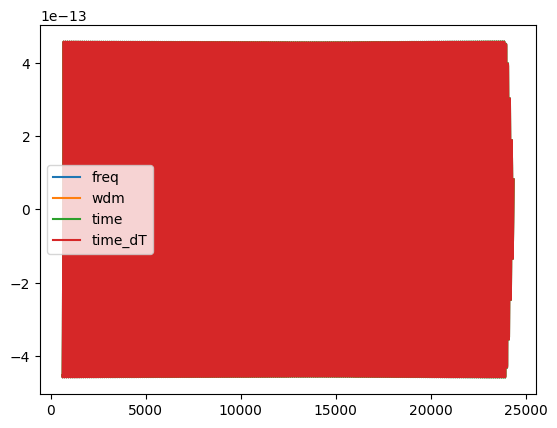

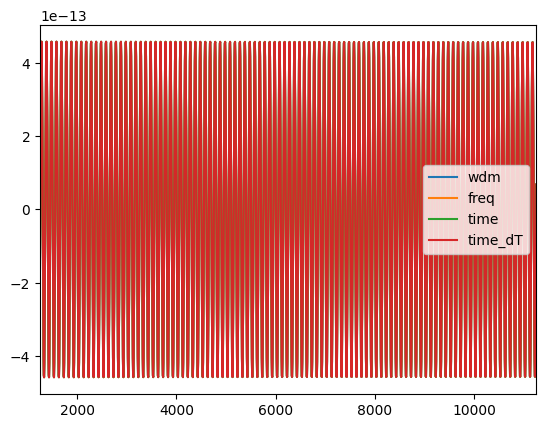

In [15]:
plotting_times = times[n_start:n_end] - times[0]

plt.plot(plotting_times, dl_sr_freq[n_start:n_end], label= "freq")
plt.plot(plotting_times, dl_sr_wdm[n_start:n_end], label="wdm")
plt.plot(plotting_times, dl_sr[n_start:n_end], label="time")
plt.plot(plotting_times, dl_sr_wdm_dT[n_start:n_end], label="time_dT")
plt.legend()
plt.show()

plt.plot(plotting_times, dl_sr_wdm[n_start:n_end], label="wdm")
plt.plot(plotting_times, dl_sr_freq[n_start:n_end], label= "freq")
plt.plot(plotting_times, dl_sr[n_start:n_end], label="time")
plt.plot(plotting_times, dl_sr_wdm_dT[n_start:n_end], label="time_dT")
plt.legend()
plt.xlim(plotting_times[n_start], plotting_times[n_start]+10000)
plt.show()

TD vs FD has stats:
1.9909008885932167e-09
1.4672892205824332e-05
TD vs WDM (no time approx) has stats:
1.2196932797081672e-08
0.0005197023267521752
TD vs WDM (time approx) has stats:
8.623317337974612e-08
0.0006605138786743731


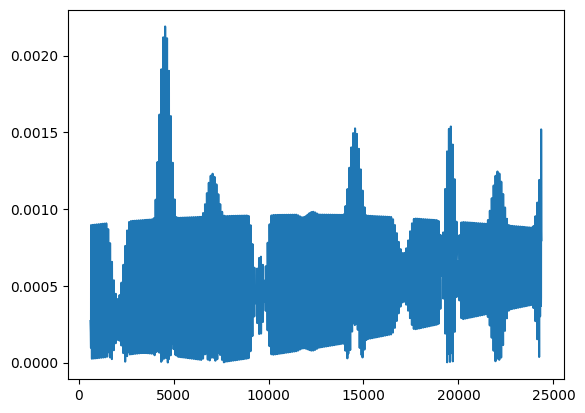

In [16]:
res1 = compare_response_signals(dl_sr[n_start:n_end], dl_sr_freq[n_start:n_end])
res2 = compare_response_signals(dl_sr[n_start:n_end], dl_sr_wdm[n_start:n_end])
res3 = compare_response_signals(dl_sr[n_start:n_end], dl_sr_wdm_dT[n_start:n_end])

print("TD vs FD has stats:")
print(res1['mismatch'])
print(res1['rel_L2'])

print("TD vs WDM (no time approx) has stats:")
print(res2['mismatch'])
print(res2['rel_L2'])

print("TD vs WDM (time approx) has stats:")
print(res3['mismatch'])
print(res3['rel_L2'])

plt.plot(plotting_times, np.abs(dl_sr[n_start:n_end]-dl_sr_wdm[n_start:n_end]) / (np.abs(dl_sr[n_start:n_end]) + 1e-30))
#plt.xlim(plotting_times[n_start], plotting_times[n_start]+1000)
plt.show()